<a href="https://colab.research.google.com/github/patiencenaserian-dotcom/DS_Course0_Week1_Module2_DataTypes/blob/main/C09_M08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Summative Lab – Analytics Firm Clients: Customer Reviews Analysis

This notebook is a **starter notebook** for the three parts of the lab:

1. NLP  
2. Time Series  
3. Neural Networks  

Use the comments and TODO prompts to guide your work. The notebook is intentionally incomplete so you can implement the analysis yourself.


## Part 1: NLP

In this section, you will clean and preprocess review text, explore frequent words and bigrams, and visualize key language patterns in the dataset.


In [33]:
# =========================
# Part 1: NLP Starter Code
# =========================

# TODO: Import the libraries you need for:
# - data handling
# - plotting
# - text preprocessing
# - tokenization / stopwords / lemmatization
# - counting words and bigrams

# Example:
# import pandas as pd

# TODO: Download any required NLTK resources.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk import bigrams
import string
from collections import Counter
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,InputLayer,Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import SparseCategoricalCrossentropy
from tensorflow.keras.metrics import SparseCategoricalAccuracy
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import classification_report, confusion_matrix



[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [5]:
# TODO: Load the dataset.
# Hint: The file used in this lab is 'amazon_reviews_lab.csv'
# df = ...
df = pd.read_csv('/content/amazon_reviews_lab (1).csv')

# TODO: Explore the dataset.
# Suggested checks:
# - shape
print(df.shape)

# - value counts for the rating column
print(df['rating'].value_counts().sort_index())

# - preview the first few rows
print(df.head())




(997, 9)
rating
1     87
2     48
3     94
4    188
5    580
Name: count, dtype: int64
   product_id  rating                                        review_text  \
0  6301977173       2  This film is definitely not for anyone who is ...   
1  6301977173       5  This movie was playing at Radio City Music Hal...   
2  6301977173       1  I would love to buy this movie as I have been ...   
3  6301977173       1  The advertisment for this DVD on Amazon was in...   
4  9575871979       5  I bought some of these to try with a light usi...   

                              review_summary review_time_raw  \
0  The best of Mark Twain's work - left out!     05 12, 2000   
1            The best Tom Sawyer i ever saw.     08 26, 2002   
2                         Why no Widescreen?      08 6, 2005   
3              False advertising on this DVD     09 11, 2005   
4                               Work GREAT!!     10 15, 2007   

   unix_review_time   timestamp sentiment_label  review_length_words  


In [6]:
# TODO: Create preprocessing tools such as:
# - stop_words
# - lemmatizer
# Create stop words and the lemmatizer
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

# TODO: Write a function called preprocess_text(text) that:
# 1. converts text to lowercase
# 2. removes URLs
# 3. removes punctuation
# 4. tokenizes the text
# 5. keeps alphabetic tokens only
# 6. removes stopwords
# 7. lemmatizes the remaining tokens
# 8. returns the cleaned tokens

# def preprocess_text(text):
def preprocess_text(text):
#lowercase
  text = text.lower()

#remove URLs
  text = re.sub(r'http\S+', '', text)

#remove punctuation
  text = re.sub(r'[^\w\s]', '', text)

#remove numbers
  text = re.sub(r'\d+', '', text)

#tokenization
  tokens = nltk.word_tokenize(text)

# Remove stop words and lemmatize words
  tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words
  ]
  return tokens



In [7]:
# TODO: Apply your preprocessing function to the review text column
# and store the output in a new column such as 'processed_tokens'.
df['processed_tokens'] = df['review_text'].apply(preprocess_text)
display(df[['review_text', 'processed_tokens']].head())


,review_text,processed_tokens
0,This film is definitely not for anyone who is ...,"[film, definitely, anyone, especially, fond, i..."
1,This movie was playing at Radio City Music Hal...,"[movie, playing, radio, city, music, hall, bac..."
2,I would love to buy this movie as I have been ...,"[would, love, buy, movie, hannibal, missouri, ..."
3,The advertisment for this DVD on Amazon was in...,"[advertisment, dvd, amazon, incorrect, ad, sta..."
4,I bought some of these to try with a light usi...,"[bought, try, light, using, work, advertised, ..."


In [8]:
# TODO: Combine all tokens into one list so you can compute word frequencies.

# Combine all processed tokens into one list
all_tokens = [word for tokens in df['processed_tokens'] for word in tokens]


In [9]:
# TODO: Use Counter to identify the most common words.
word_counts = Counter(all_tokens)

# Display the 10 most common words
print(word_counts.most_common(10))


[('nook', 1516), ('book', 914), ('one', 569), ('kindle', 566), ('screen', 498), ('like', 460), ('read', 454), ('work', 447), ('get', 424), ('great', 422)]


In [10]:
# TODO: Generate bigrams from the token list and identify the most common bigrams.
all_bigrams = [
    pair
    for tokens in df['processed_tokens']
    for pair in bigrams(tokens)
]

# Count the most common bigrams
bigram_counts = Counter(all_bigrams)

# Display the top 10 bigrams
print(bigram_counts.most_common(10))


[(('barnes', 'noble'), 152), (('nook', 'color'), 128), (('battery', 'life'), 87), (('touch', 'screen'), 82), (('sd', 'card'), 82), (('nook', 'hd'), 74), (('work', 'great'), 63), (('nook', 'tablet'), 63), (('kindle', 'fire'), 58), (('work', 'well'), 57)]


In [11]:
# TODO: Create at least one visualization of the most common words.
# You may also choose to visualize the most common bigrams.

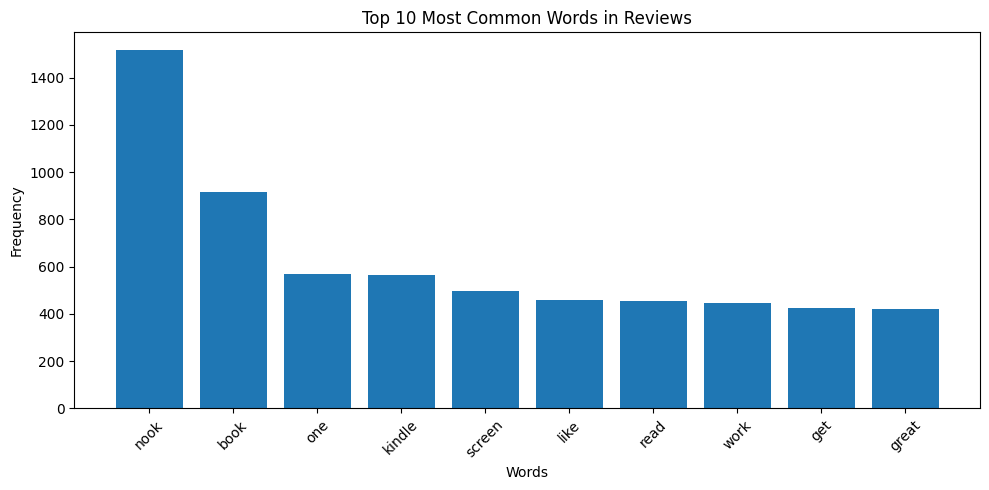

In [12]:
# Visualize the 10 most common words
top_words = word_counts.most_common(10)
words, counts = zip(*top_words)

plt.figure(figsize=(10, 5))
plt.bar(words, counts)
plt.title('Top 10 Most Common Words in Reviews')
plt.xlabel('Words')
plt.ylabel('Frequency')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

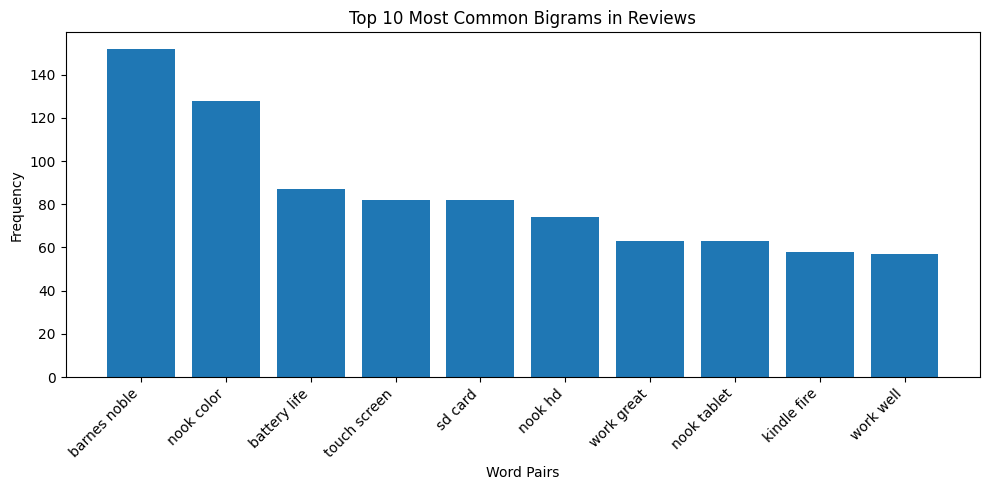

In [13]:
# Visualize the 10 most common bigrams
top_bigrams = bigram_counts.most_common(10)
phrases = [' '.join(pair) for pair, count in top_bigrams]
bigram_counts_values = [count for pair, count in top_bigrams]

plt.figure(figsize=(10, 5))
plt.bar(phrases, bigram_counts_values)
plt.title('Top 10 Most Common Bigrams in Reviews')
plt.xlabel('Word Pairs')
plt.ylabel('Frequency')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [14]:
# Reflection prompt:
# What do the most common words or phrases suggest about customer sentiment or product experience?


The most common words, such as “nook,” “book,” and “kindle,” suggest that customers frequently discuss e-readers and reading experiences. Common phrases like “battery life” and “touch screen” show that customers are interested in device performance and features. The phrase “work great” suggests positive experiences with the products. Overall, the reviews cover both product features and customer satisfaction, although the most common words alone cannot determine the overall sentiment.

## Part 2: Time Series

In this section, you will analyze review activity over time by converting timestamps, resampling the data, and visualizing trends in review volume and ratings.


In [15]:
# ==============================
# Part 2: Time Series Starter Code
# ==============================

# TODO: Convert the timestamp column to datetime format.
# Convert timestamp to datetime
df['timestamp'] = pd.to_datetime(df['timestamp'])

# Display the first 5 rows
df[['timestamp', 'rating']].head()


# Reflection prompt:
# What overall trends do you notice in review activity and customer ratings over time?


,timestamp,rating
0,2000-05-12,2
1,2002-08-26,5
2,2005-08-06,1
3,2005-09-11,1
4,2007-10-15,5


In [17]:
# TODO: Inspect the date range in the dataset.
# Suggested checks:
# - earliest timestamp
# - latest timestamp

# Check the earliest timestamp
print("Earliest date:", df['timestamp'].min())

# Check the latest timestamp
print("Latest date:", df['timestamp'].max())

Earliest date: 2000-05-12 00:00:00
Latest date: 2014-07-17 00:00:00


In [20]:
# TODO: Resample the data by month to calculate:
# 1. monthly review count
# 2. monthly average rating

# Suggested variable names:
# monthly_review_count = ...
# monthly_avg_rating = ...

# Resample data by month
monthly_reviews = df.resample('ME', on='timestamp').agg(
    monthly_review_count=('rating', 'count'),
    monthly_average_rating=('rating', 'mean')
)

print(monthly_reviews)

            monthly_review_count  monthly_average_rating
timestamp                                               
2000-05-31                     1                2.000000
2000-06-30                     0                     NaN
2000-07-31                     0                     NaN
2000-08-31                     0                     NaN
2000-09-30                     0                     NaN
...                          ...                     ...
2014-03-31                    30                4.333333
2014-04-30                    22                4.000000
2014-05-31                    12                4.250000
2014-06-30                    15                4.533333
2014-07-31                    13                4.000000

[171 rows x 2 columns]


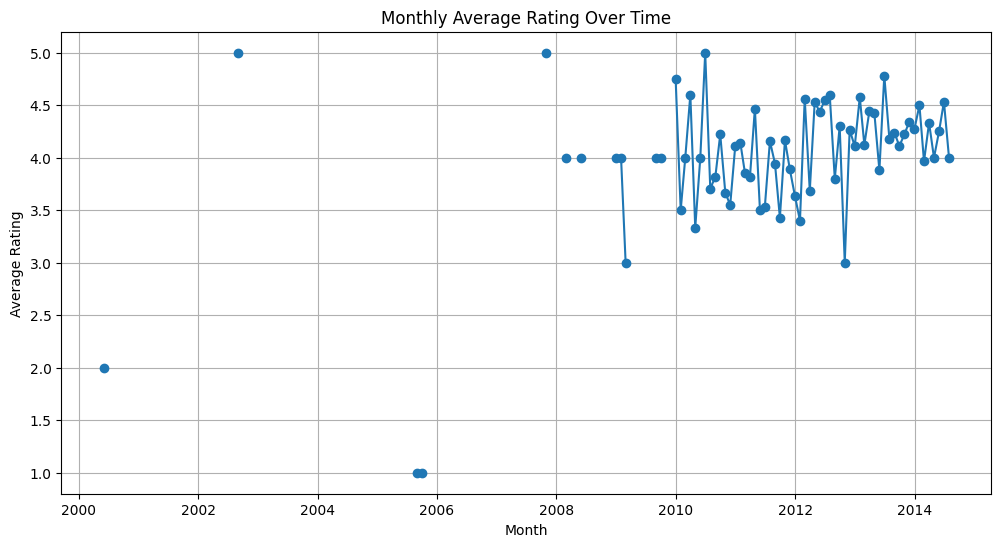

In [21]:
# TODO: Plot average monthly rating over time.
plt.figure(figsize=(12, 6))
plt.plot(monthly_reviews.index, monthly_reviews['monthly_average_rating'], marker='o', linestyle='-')
plt.title('Monthly Average Rating Over Time')
plt.xlabel('Month')
plt.ylabel('Average Rating')
plt.grid(True)
plt.show()



In [23]:
# TODO: Compute a rolling average for the monthly average rating.
# A 3-month rolling average is a good starting point.
monthly_reviews['rolling_average_rating'] = (
    monthly_reviews['monthly_average_rating'].rolling(window=3).mean()
)

# Display all results
display(monthly_reviews)

,monthly_review_count,monthly_average_rating,rolling_average_rating
timestamp,,,
2000-05-31,1,2.000000,NaN
2000-06-30,0,NaN,NaN
2000-07-31,0,NaN,NaN
2000-08-31,0,NaN,NaN
2000-09-30,0,NaN,NaN
...,...,...,...
2014-03-31,30,4.333333,4.265873
2014-04-30,22,4.000000,4.099206
2014-05-31,12,4.250000,4.194444


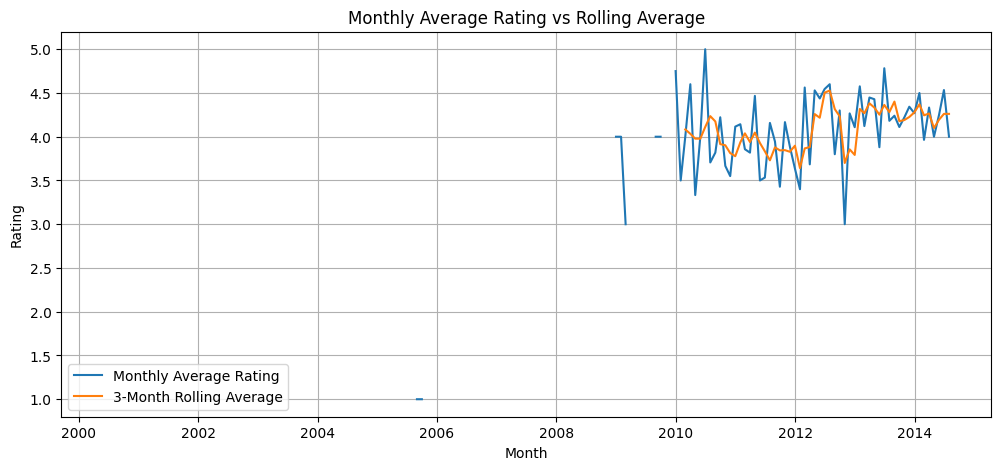

In [24]:
# TODO: Plot both:
# - the original monthly average rating
# - the rolling average
# on the same figure.

plt.figure(figsize=(12, 5))

plt.plot(monthly_reviews.index,
         monthly_reviews['monthly_average_rating'],
         label='Monthly Average Rating')

plt.plot(monthly_reviews.index,
         monthly_reviews['rolling_average_rating'],
         label='3-Month Rolling Average')

plt.title('Monthly Average Rating vs Rolling Average')
plt.xlabel('Month')
plt.ylabel('Rating')
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# Reflection prompt:
# What overall trends do you notice in review activity and customer ratings over time?


Review activity varies over time, with more reviews appearing in later years. Customer ratings fluctuate from month to month, but they generally remain around 4 out of 5. The 3-month rolling average smooths out these fluctuations and makes the overall trend easier to understand. Overall, customer ratings appear relatively stable, despite some noticeable increases and decreases over time.

## Part 3: Neural Networks

In this section, you will transform text reviews into numerical features, train a neural network to predict ratings, and evaluate model performance.


In [28]:
# ===================================
# Part 3: Neural Networks Starter Code
# ===================================

#TODO: Define:
# X as the review text column
# y as the rating column
# If needed, adjust y so the classes are numbered appropriately for your model.

# X as the review text column
X = df['review_text']

# y as the rating column
y = df['rating']

# Adjust ratings to start from 0 if needed
y = y - 1


In [29]:
# TODO: Vectorize the text using TF-IDF.
# Suggested question:
# - How many features do you want to keep?

# vectorizer = ...
# X_tfidf = ...


# Vectorize the text using TF-IDF
vectorizer = TfidfVectorizer(max_features=5000)

X_tfidf = vectorizer.fit_transform(X)

# Check the shape
print("TF-IDF shape:", X_tfidf.shape)


TF-IDF shape: (997, 5000)


In [30]:
# TODO: Split the data into training and testing sets.
# Use stratify=y to preserve class balance.

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [31]:
# TODO: One-hot encode the target values if your neural network setup requires it.

# One-hot encode the target values
y_train_encoded = to_categorical(y_train, num_classes=5)
y_test_encoded = to_categorical(y_test, num_classes=5)

# Check the shapes
print("Encoded training labels:", y_train_encoded.shape)
print("Encoded testing labels:", y_test_encoded.shape)


Encoded training labels: (797, 5)
Encoded testing labels: (200, 5)


In [34]:
# TODO: Build a neural network model.
# Include:
# - an input layer
# - at least one hidden layer
# - an output layer suitable for multi-class classification

# model = ...


# Build the neural network model
model = Sequential([
    # Input layer and first hidden layer
    Dense(128, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.3),

    # Second hidden layer
    Dense(64, activation='relu'),
    Dropout(0.2),

    # Output layer for 5 rating classes
    Dense(5, activation='softmax')
])

# Display the model architecture
model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 128)            │       640,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 648,709 (2.47 MB)

 Trainable params: 648,709 (2.47 MB)

 Non-trainable params: 0 (0.00 B)

In [35]:
# TODO: Compile the model.
# Think about:
# - optimizer
# - loss function
# - evaluation metric(s)

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [36]:
# TODO: Train the model and store the training history.
# history = ...

history = model.fit(
    X_train.toarray(),
    y_train_encoded,
    epochs=10,
    batch_size=32,
    validation_split=0.2)

Epoch 1/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.5165 - loss: 1.5390 - val_accuracy: 0.5813 - val_loss: 1.4120
Epoch 2/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5824 - loss: 1.2997 - val_accuracy: 0.5813 - val_loss: 1.2469
Epoch 3/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5824 - loss: 1.1253 - val_accuracy: 0.5813 - val_loss: 1.1840
Epoch 4/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5824 - loss: 0.9945 - val_accuracy: 0.5813 - val_loss: 1.1394
Epoch 5/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6154 - loss: 0.8304 - val_accuracy: 0.5875 - val_loss: 1.1128
Epoch 6/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7284 - loss: 0.6674 - val_accuracy: 0.5750 - val_loss: 1.1130
Epoch 7/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8210 - loss: 0.5069 - val_accuracy: 0.5562 - val_loss: 1.1470
Epoch 8/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8964 - loss: 0.3760 - val_accuracy: 0.5625 - v

In [37]:
# TODO: Evaluate the model on the test set
test_loss, test_accuracy = model.evaluate(
    X_test.toarray(),
    y_test_encoded
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5550 - loss: 1.3222  
Test Loss: 1.322197437286377
Test Accuracy: 0.5550000071525574


In [38]:
# Generate predictions on the test set
y_pred_prob = model.predict(X_test.toarray())

# Convert probabilities into predicted classes
y_pred = np.argmax(y_pred_prob, axis=1)

# Display the first 10 predictions
print("Predicted ratings:", y_pred[:10] + 1)
print("Actual ratings:", y_test[:10].to_numpy() + 1)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
Predicted ratings: [5 5 5 5 5 5 5 5 5 5]
Actual ratings: [5 1 4 4 5 1 5 5 5 5]


Classification Report:
              precision    recall  f1-score   support

      1 star       0.29      0.12      0.17        17
     2 stars       0.00      0.00      0.00        10
     3 stars       0.00      0.00      0.00        19
     4 stars       0.22      0.18      0.20        38
     5 stars       0.64      0.88      0.74       116

    accuracy                           0.56       200
   macro avg       0.23      0.24      0.22       200
weighted avg       0.44      0.56      0.48       200



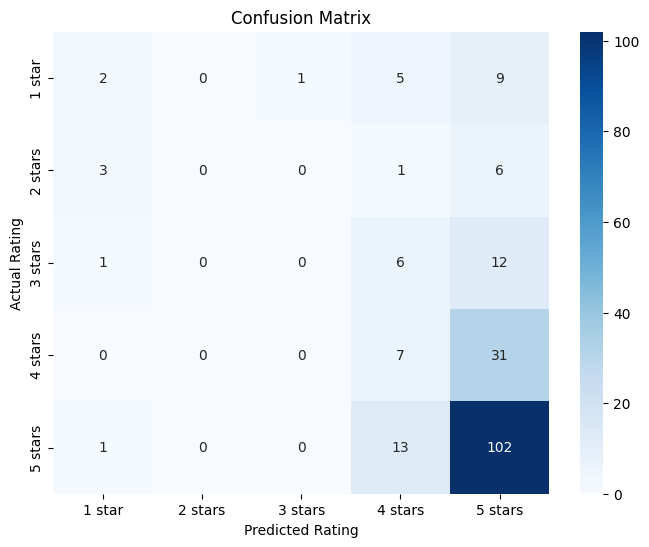

In [39]:
# TODO: Create a classification report and/or confusion matrix to assess performance.
# Create a classification report
print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=['1 star', '2 stars', '3 stars', '4 stars', '5 stars'],
    zero_division=0
))

# Create a confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2, 3, 4])

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['1 star', '2 stars', '3 stars', '4 stars', '5 stars'],
    yticklabels=['1 star', '2 stars', '3 stars', '4 stars', '5 stars']
)

plt.xlabel('Predicted Rating')
plt.ylabel('Actual Rating')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
# Reflection prompt:
# Which rating classes does the model predict well, and which ones are harder to classify?


The model predicts 5-star ratings best, with a recall of 0.88 and an F1-score of 0.74. However, it struggles to classify 2-star and 3-star ratings, with F1-scores of 0.00. The model also has difficulty identifying 1-star and 4-star reviews. This may be due to the imbalance in the dataset, as there are many more 5-star reviews than the other ratings. Overall, the results suggest that the model is biased toward predicting 5-star ratings and needs improvement to classify all rating classes more accurately.